In [1]:
import pandas as pd
import matplotlib.pyplot as plt




## Clean data:
We note that each song within a top 200 playlist has multiple entries depending on the number of artists. to resolve this, we split into primary artists and featured artists. We then reinsert each entry back into the original dataset, to obtain 1 row per song per playlist

In [11]:
import pandas as pd

originalDF = pd.read_csv('data/Spotify_Dataset_V3.csv', delimiter=';')
dataDF = pd.read_csv('data/data.csv')

# create id, date keys to merge on (one row per (id, Date))
uniqueOrig = originalDF[['id', 'Date']].drop_duplicates()

# Prepare right-hand side for a many-to-one merge on id:
# - drop Date to avoid Date_x/Date_y
# - ensure at most one row per id
dfToMerge = (
    dataDF
    .drop(columns=['Date'], errors='ignore')
    .drop_duplicates(subset='id', keep='first')
)

# Merge: replicate track-level features across all dates
dfFinal = uniqueOrig.merge(
    dfToMerge,
    on=['id'],
    how='left',
    validate='m:1'   # many (dates) to one (track row)
)

# Extract lyrics field, save to csv with associated id, remove from dfFinal
lyrics = dfFinal[['id', 'lyrics']].drop_duplicates('id')
# lyrics.to_csv('data/lyrics.csv', index=False)

# drop lyrics from dfFinal
dfFinal = dfFinal.drop(['lyrics'], axis=1, errors='ignore')
dfFinal.columns

# summarise dfFinal
dfFinal.info()
dfFinal.head()

# Optionally verify we didn’t lose any data
# print(f"Original unique entries: {len(uniqueOrig)}")
# print(f"Final merged entries: {len(dfFinal)}")

dfFinal.to_csv('data/spotifyNoRowDuplicates.csv.gz', index=False, compression='gzip')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467061 entries, 0 to 467060
Data columns (total 28 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    467061 non-null  object 
 1   Date                  467061 non-null  object 
 2   Rank                  467061 non-null  int64  
 3   Title                 467061 non-null  object 
 4   Primary Artists       464687 non-null  object 
 5   Featuring Artists     94214 non-null   object 
 6   Danceability          467061 non-null  float64
 7   Energy                467061 non-null  float64
 8   Speechiness           467061 non-null  float64
 9   Acousticness          467061 non-null  float64
 10  Instrumentalness      467061 non-null  float64
 11  Valence               467061 non-null  float64
 12  Nationality           467061 non-null  object 
 13  Continent             467061 non-null  object 
 14  Points (Total)        467061 non-null  int64  
 15  

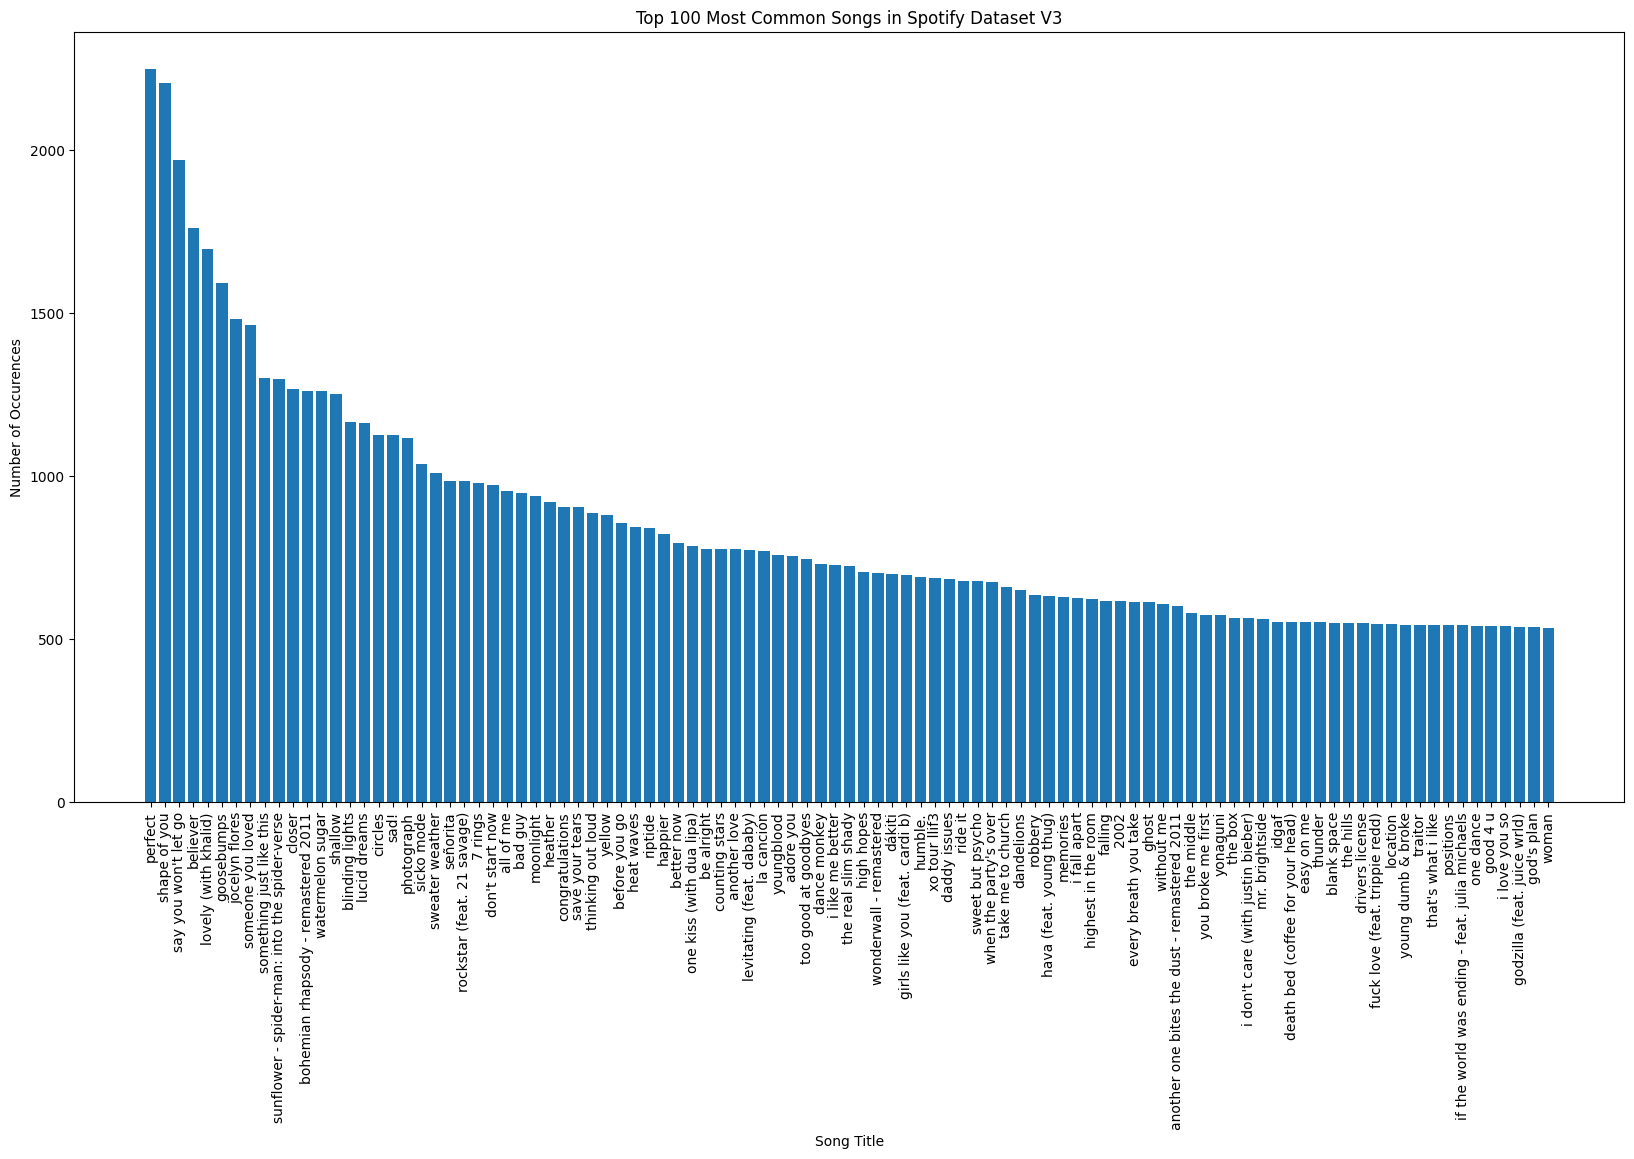

In [12]:
# count occurences of each individual id
id_counts = dfFinal.groupby('id').agg(count=('id','size'), Title=('Title','first')).reset_index().sort_values('count', ascending=False)
id_counts

# plot top 100 most common songs as bar chart
top_100 = id_counts.head(100)
plt.figure(figsize=(20,10))
plt.bar(top_100['Title'], top_100['count'])
plt.xticks(rotation=90)
plt.xlabel('Song Title')
plt.ylabel('Number of Occurences')
plt.title('Top 100 Most Common Songs in Spotify Dataset V3')
plt.show()







In [7]:
# Sanity checks
assert not dfFinal.duplicated(['id','Date']).any(), "Found duplicate (id, Date) rows."
assert dfFinal['Rank'].dropna().between(1, 200).all(), "Some ranks are outside 1–200."

# Count unique days on chart per track
id_counts = (
    dfFinal[dfFinal['Rank'].between(1, 200)]
    .groupby('id')
    .agg(days_on_chart=('Date', 'nunique'),
         Title=('Title', 'first'))
    .reset_index()
    .sort_values('days_on_chart', ascending=False)
)

# Plot top 100
top_100 = id_counts.head(100)
plt.figure(figsize=(20,10))
plt.bar(top_100['Title'], top_100['days_on_chart'])
plt.xticks(rotation=90)
plt.xlabel('Song Title')
plt.ylabel('Number of Days in Top 200')
plt.title('Top 100 Most Persistent Songs in Top 200')
plt.tight_layout()
plt.show()


KeyError: Index(['Date'], dtype='object')

# Create leaderboard of artists by total points
Include each time they appear as primary/featured artists

In [ ]:
df = pd.read_csv('data/spotifyNoRowDuplicates.csv.gz', compression='gzip')





# Plot Historical Popularity of individual songs

In [ ]:
# want to create function which will:
# (1) search for all entries of song within dataset
# (2) sort dates
# (3) plot points over time

def historicalPopularity(df, id):
    # given song title, search for all entries of song within dataset
    allEntries = df.loc[df['id'] == id]

    

    allEntries['Date'] = pd.to_datetime(allEntries['Date'], dayfirst=True)
    
    # Sort allEntries by the date
    sortedAllEntries = allEntries.sort_values(by='Date')
    print(sortedAllEntries)
    
    # Plotting Points over time
    plt.figure(figsize=(10, 5))  # Set the figure size for better readability
    plt.bar(sortedAllEntries['Date'], sortedAllEntries['Points (Total)'], color='blue')

    # get title from id
    title = df.loc[df['id'] == id, 'Title'].values[0]
    artist = df.loc[df['id'] == id, 'Artists'].values[0]

    # Adding titles and labels
    plt.title(f'Historical Popularity of Song ID {title} by {artist}')
    plt.xlabel('Date')
    plt.ylabel('Total Points')
    plt.xticks(rotation=45)  # Rotate date labels for better visibility
    plt.tight_layout()  # Adjust layout to make room for the rotated date labels
    plt.show()


df = pd.read_csv('data/Spotify_Dataset_V3.csv', delimiter=';')

id = '73SpzrcaHk0RQPFP73vqVR'

historicalPopularity(df, id)

